# 05d — Eksperimen Ablasi Morfologi Terkontrol (`Otsu` & `K-Means k=4`)

Notebook ini melanjutkan temuan diagnostik [`05c_morphology_diagnostic.ipynb`](05c_morphology_diagnostic.ipynb) menggunakan **protokol ketat `v3` (`StratifiedGroupKFold` 5-fold, upstream fit per-fold, scaler per-fold, Set A `appearance.csv` bersama tanpa rekomputasi, zero tuning pada `val`, zero akses `test`)**.

Empat kandidat terkontrol dibandingkan secara berpasangan terhadap baseline immutabel `M0`, `M1` (hapus komponen 8-connected `< 16 px`), dan `M2` (`M1 + 3×3 cross OPEN + CLOSE`):
1. `close_only`: `M1` + *closing* `3×3` cross.
2. `open_only`: `M1` + *opening* `3×3` cross.
3. `m2_area16`: `M2` + hapus komponen `< 16 px` hasil re-fragmentasi *opening*.
4. `hole_fill_small`: `M1` + *selective hole filling* (hanya lubang interior 4-connected tertutup dengan luas `<= 15 px`, batas pra-tetap simetris terhadap `< 16 px`).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from ebhi_dip.morphology_ablation import (
    ALL_VARIANTS,
    MAX_SMALL_HOLE_AREA,
    PREDECLARED_ANCHOR_SPECS,
    load_saved_ablation_outputs,
    plot_ablation_cv_macro_f1,
    plot_ablation_delta_dice_distributions,
    plot_ablation_feature_shifts,
    plot_ablation_per_category_f1,
    plot_ablation_pixel_flips_and_components,
    plot_ablation_segmentation_overview,
    plot_case_ablation_gallery,
    plot_dice_up_cls_flip_example,
)
from ebhi_dip.morphology_diagnostic import file_sha256_map
from ebhi_dip.plotting import configure_notebook_style, finish_figure

EXPORT_FIGURES = False
configure_notebook_style()

TRACKED_INPUTS = (
    "data/metadata/split_manifest.csv",
    "data/metadata/split_manifest.sha256",
    "results/features/appearance.csv",
    "configs/otsu_raw.json",
    "models/kmeans_lab_k4_mapped.json",
    "results/classification_2x3_strict/fold_upstream_audit.json",
    "results/classification_2x3_strict/svm_2x3_strict_grid_results.csv",
)
input_hashes_before = file_sha256_map(ROOT, TRACKED_INPUTS)

outputs = load_saved_ablation_outputs(ROOT)
manifest = outputs.manifest
assert manifest["train_images"] == 1535
assert manifest["val_readonly_images"] == 372
assert manifest["test_images_touched"] == 0 and manifest["test_labels_accessed"] is False
assert manifest["max_small_hole_area_predeclared"] == MAX_SMALL_HOLE_AREA == 15

protocol_tbl = pd.DataFrame(
    [
        {"parameter": "Train cohort (Strict 5-fold CV)", "nilai": f"{manifest['train_images']} citra / {manifest['train_groups']} grup"},
        {"parameter": "Validation cohort (read-only)", "nilai": f"{manifest['val_readonly_images']} citra / {manifest['val_readonly_groups']} grup (0 tuning)"},
        {"parameter": "Held-out test touched", "nilai": f"{manifest['test_images_touched']} citra (akses={manifest['test_labels_accessed']})"},
        {"parameter": "Cutoff lubang internal predeclared", "nilai": f"<= {manifest['max_small_hole_area_predeclared']} px (4-connected interior only)"},
        {"parameter": "Anchor SVM predeclared", "nilai": ", ".join(s["spec_id"] for s in PREDECLARED_ANCHOR_SPECS)},
    ]
)
display(protocol_tbl)

,parameter,nilai
0,Train cohort (Strict 5-fold CV),1535 citra / 247 grup
1,Validation cohort (read-only),372 citra / 53 grup (0 tuning)
2,Held-out test touched,0 citra (akses=False)
3,Cutoff lubang internal predeclared,<= 15 px (4-connected interior only)
4,Anchor SVM predeclared,"lin_none_C3, rbf_bal_C3_g001, rbf_bal_C10_g001..."


## 1. Dampak Segmentasi (`train OOF` `n = 1.535` & Referensi `val` Read-Only `n = 372`)

Pengukuran segmentasi dipisahkan antara perilaku batas/piksel (*Dice, IoU, Precision, Recall, FG coverage*, komponen `< 16 px`, lubang interior) dan fitur hilir.

In [2]:
seg_cols = [
    "family", "variant", "macro_dice", "macro_delta_dice_vs_M0", "macro_delta_dice_vs_M1",
    "macro_iou", "macro_precision", "macro_recall", "macro_fg_pct",
    "mean_cc_count", "mean_small_cc_count", "mean_hole_count", "mean_small_hole_count",
    "improve_vs_M1_n", "negligible_vs_M1_n", "regress_vs_M1_n",
]
display(
    outputs.seg_train_summary[seg_cols].style.format(
        {
            "macro_dice": "{:.4f}",
            "macro_delta_dice_vs_M0": "{:+.4f}",
            "macro_delta_dice_vs_M1": "{:+.4f}",
            "macro_iou": "{:.4f}",
            "macro_precision": "{:.4f}",
            "macro_recall": "{:.4f}",
            "macro_fg_pct": "{:.2f}%",
            "mean_cc_count": "{:.1f}",
            "mean_small_cc_count": "{:.1f}",
            "mean_hole_count": "{:.1f}",
            "mean_small_hole_count": "{:.1f}",
        }
    )
)

,family,variant,macro_dice,macro_delta_dice_vs_M0,macro_delta_dice_vs_M1,macro_iou,macro_precision,macro_recall,macro_fg_pct,mean_cc_count,mean_small_cc_count,mean_hole_count,mean_small_hole_count,improve_vs_M1_n,negligible_vs_M1_n,regress_vs_M1_n
0,otsu,M0,0.6834,+0.0000,+0.0001,0.5316,0.7444,0.6505,54.32%,196.9,135.4,340.1,300.8,198,1012,325
1,otsu,M1,0.6833,-0.0001,+0.0000,0.5321,0.7547,0.6445,53.14%,61.5,0.0,339.9,300.6,0,1535,0
2,otsu,M2,0.6818,-0.0016,-0.0015,0.5330,0.7586,0.6423,52.68%,68.0,24.5,59.9,32.7,766,310,459
3,otsu,close_only,0.7001,+0.0168,+0.0169,0.5527,0.7398,0.6862,57.84%,27.2,0.0,107.7,57.8,1268,214,53
4,otsu,open_only,0.6692,-0.0141,-0.0140,0.5177,0.7672,0.6153,49.84%,114.6,41.3,224.1,203.7,143,381,1011
5,otsu,m2_area16,0.6809,-0.0025,-0.0024,0.5323,0.7615,0.6394,52.26%,43.5,0.0,59.9,32.7,782,280,473
6,otsu,hole_fill_small,0.6945,+0.0111,+0.0112,0.5460,0.7541,0.6652,54.93%,61.5,0.0,39.3,0.0,1305,225,5
7,k4,M0,0.7521,+0.0000,+0.0005,0.6137,0.6729,0.8779,82.23%,29.3,22.9,399.8,350.7,6,1508,21
8,k4,M1,0.7516,-0.0005,+0.0000,0.6134,0.6741,0.8766,82.04%,6.3,0.0,399.8,350.6,0,1535,0
9,k4,M2,0.7510,-0.0011,-0.0006,0.6134,0.6679,0.8854,83.65%,7.8,2.7,80.0,42.9,304,939,292


In [3]:
val_cols = [
    "family", "variant", "macro_dice", "macro_delta_dice_vs_M0", "macro_delta_dice_vs_M1",
    "macro_precision", "macro_recall", "macro_fg_pct",
    "mean_cc_count", "mean_small_cc_count", "improve_vs_M1_n", "regress_vs_M1_n",
]
display(
    outputs.seg_val_summary[val_cols].style.format(
        {
            "macro_dice": "{:.4f}",
            "macro_delta_dice_vs_M0": "{:+.4f}",
            "macro_delta_dice_vs_M1": "{:+.4f}",
            "macro_precision": "{:.4f}",
            "macro_recall": "{:.4f}",
            "macro_fg_pct": "{:.2f}%",
            "mean_cc_count": "{:.1f}",
            "mean_small_cc_count": "{:.1f}",
        }
    )
)

,family,variant,macro_dice,macro_delta_dice_vs_M0,macro_delta_dice_vs_M1,macro_precision,macro_recall,macro_fg_pct,mean_cc_count,mean_small_cc_count,improve_vs_M1_n,regress_vs_M1_n
0,otsu,M0,0.7232,+0.0000,-0.0016,0.7776,0.6935,56.65%,218.2,151.8,52,101
1,otsu,M1,0.7248,+0.0016,+0.0000,0.7894,0.6884,55.46%,66.4,0.0,0,0
2,otsu,M2,0.7288,+0.0056,+0.0040,0.7969,0.6924,55.24%,75.9,27.9,196,117
3,otsu,close_only,0.7442,+0.0209,+0.0194,0.7761,0.7340,60.16%,29.4,0.0,320,4
4,otsu,open_only,0.7135,-0.0097,-0.0113,0.8038,0.6617,52.34%,127.1,46.7,37,255
5,otsu,m2_area16,0.7287,+0.0055,+0.0039,0.8007,0.6901,54.83%,48.0,0.0,197,123
6,otsu,hole_fill_small,0.7374,+0.0142,+0.0126,0.7894,0.7113,57.29%,66.4,0.0,328,0
7,k4,M0,0.7761,+0.0000,+0.0001,0.6957,0.9052,83.85%,27.9,23.5,2,0
8,k4,M1,0.7760,-0.0001,+0.0000,0.6962,0.9042,83.70%,4.5,0.0,0,0
9,k4,M2,0.7753,-0.0007,-0.0006,0.6898,0.9138,85.47%,6.6,2.7,75,90


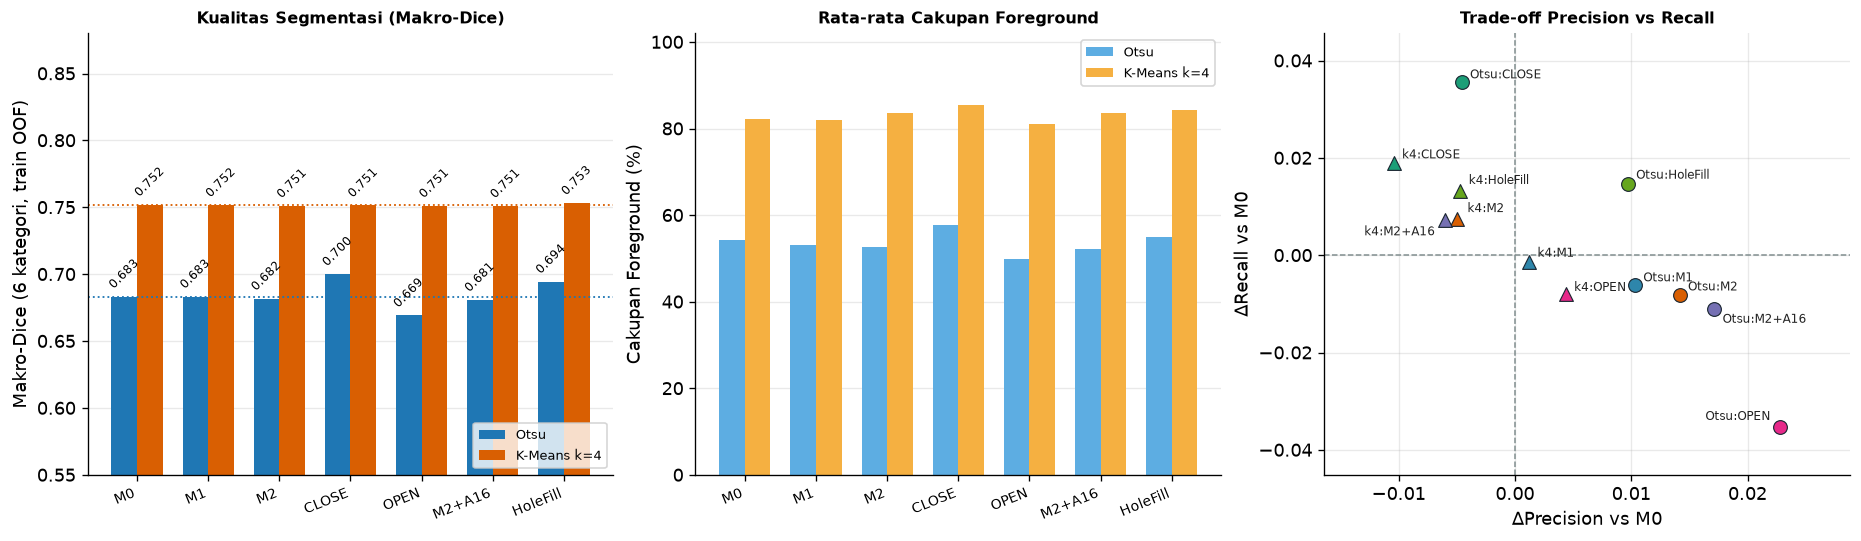

In [4]:
fig_seg = plot_ablation_segmentation_overview(outputs.seg_train_summary)
finish_figure(fig_seg, show=True, close=True)

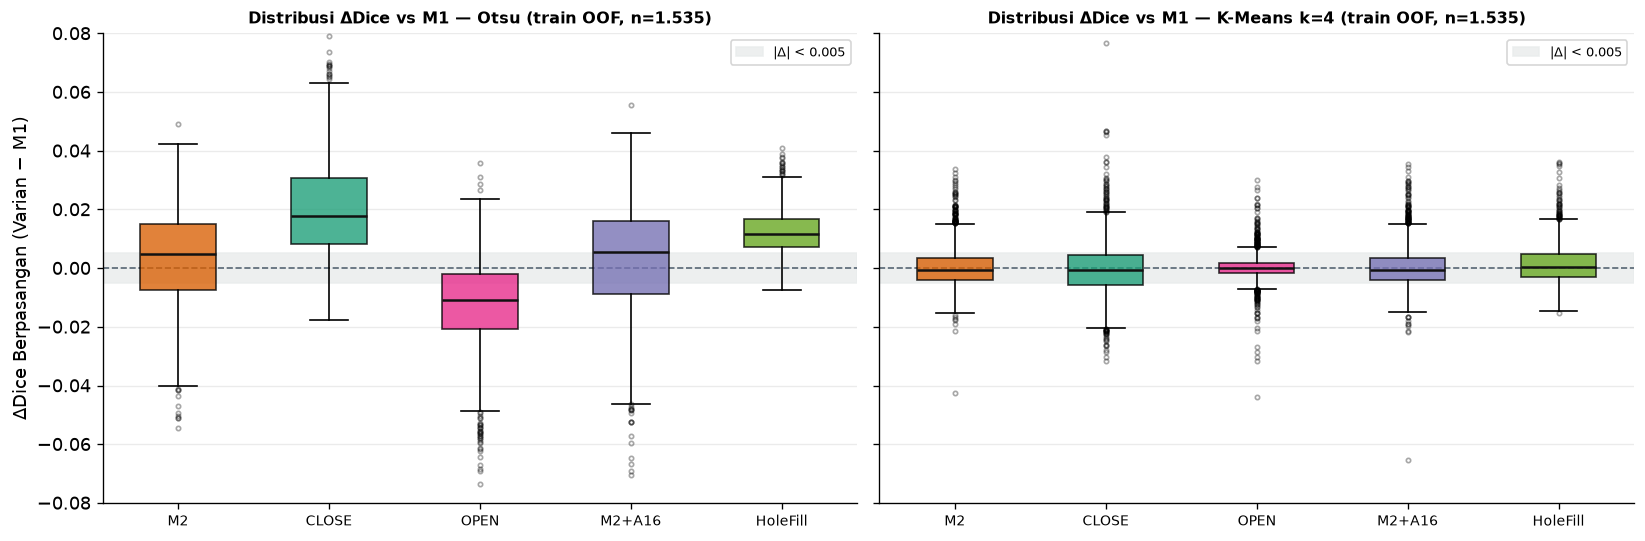

In [5]:
fig_dd = plot_ablation_delta_dice_distributions(outputs.seg_train_per_image)
finish_figure(fig_dd, show=True, close=True)

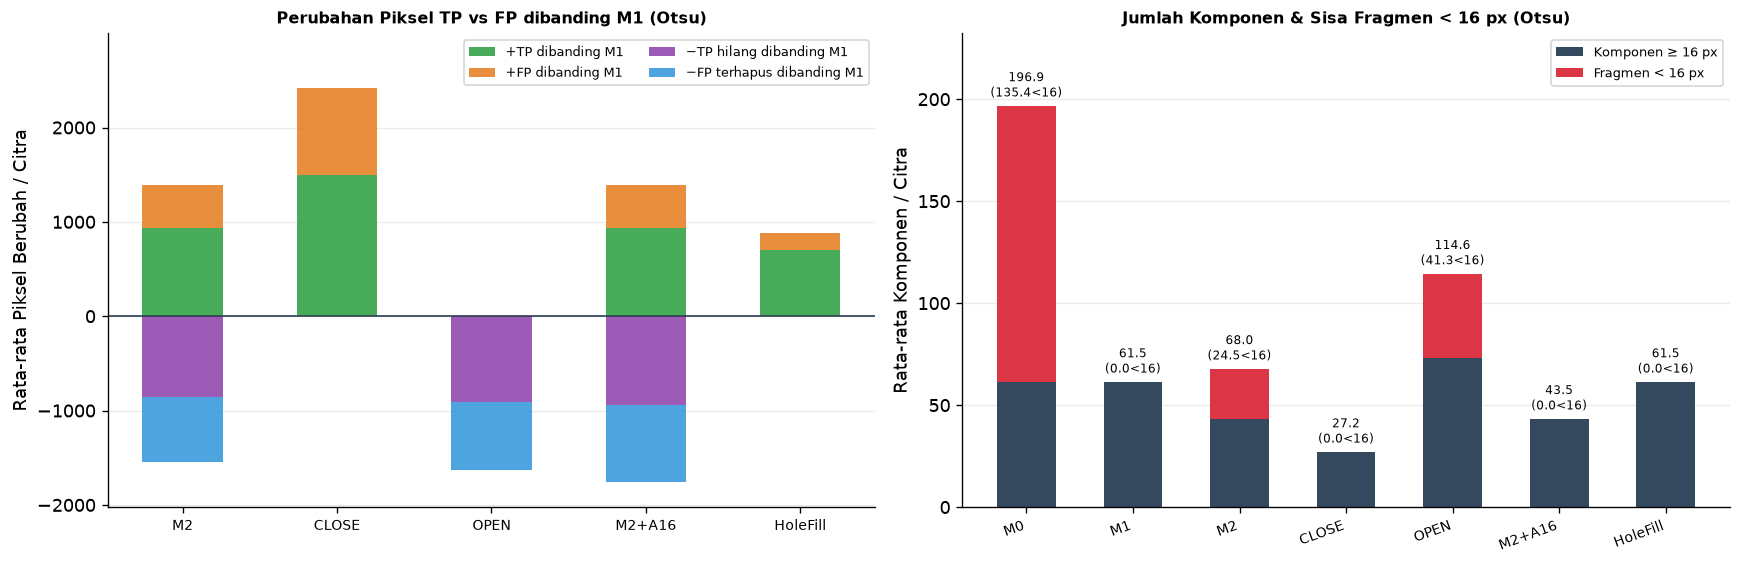

In [6]:
fig_px = plot_ablation_pixel_flips_and_components(outputs.seg_train_summary)
finish_figure(fig_px, show=True, close=True)

In [7]:
area_piv = (
    outputs.area_distributions
    .pivot(index=["family", "variant"], columns="area_bin", values="share_pct")
    .loc[[(f, v) for f in ("otsu", "k4") for v in ALL_VARIANTS], ["1", "2–4", "5–15", "16–31", "32–127", "128–1023", "≥1024"]]
)
display(area_piv.style.format("{:.2f}%"))

**Temuan segmentasi utama (`train OOF`):**
- **`close_only` meraih Makro-Dice Otsu tertinggi (`0.7001`, `+0.0168` vs `M0`):** mengisi celah kelenjar (`+1.499,8 TP px` vs `+918,8 FP px` relatif `M1`) dan menggabungkan region (`mean_cc` turun `61,5 -> 27,2`; `1.268/1.535` citra membaik vs `M1`).
- **`hole_fill_small` adalah perbaikan paling konservatif & bersih (`0.6945`, `+0.0111` vs `M0`):** meningkatkan *Recall* (`0.6445 -> 0.6652`) hampir tanpa merusak *Precision* (`0.7547 -> 0.7541`), menambah `3,75×` lebih banyak piksel TP daripada FP (`+698,7 TP` vs `+186,4 FP`), menaikkan Dice pada **`1.305/1.535` citra**, dan hanya menurunkan **5 citra**!
- **`open_only` merusak segmentasi Otsu (`0.6692`, `-0.0141` vs `M0`):** mengikis dinding tipis (`-903,8 TP px` di bawah `M1`, `1.011/1.535` regresi) dan merefragmentasi objek hampir dua kali lipat (`61,5 -> 114,6` komponen) dengan **`41,3` fragmen `< 16 px` baru per citra** (`36,1%` total komponen).
- **`m2_area16` mengonfirmasi hipotesis fragmentasi `M2`:** menghapus `24,5` sisa fragmen `< 16 px` (`36,1%` komponen di `M2`), meski menurunkan Dice sedikit (`0.6818 -> 0.6809`).
- **Keluarga `k4` tidak sensitif di sisi Dice (`0.7509–0.7532`):** cakupan sudah sangat tinggi (`82,0–85,5%`), sehingga hanya `hole_fill_small` yang membersihkan `350,6` lubang kecil/citra dengan sedikit keunggulan `+0.0016` atas `M1`.

## 2. Perubahan Fitur Morfologi Set B (`19` Fitur)

Morfologi mask mengubah distribusi 19 fitur Set B secara sangat asimetris — terutama fitur median berbasis distribusi komponen (`region_area_rel_median`, `region_perimeter_rel_median`) dan `region_solidity_mean`.

In [8]:
fs_o = (
    outputs.feature_shifts.loc[outputs.feature_shifts["family"].eq("otsu")]
    .pivot(index="feature", columns="variant", values="mean_abs_std_shift_vs_M0")[
        ["M1", "M2", "close_only", "open_only", "m2_area16", "hole_fill_small"]
    ]
)
top_shift = fs_o.reindex(fs_o.max(axis=1).sort_values(ascending=False).index)
display(top_shift.style.format("{:.3f}"))

variant,M1,M2,close_only,open_only,m2_area16,hole_fill_small
feature,,,,,,
region_area_rel_median,74.880,22.908,280.514,7.545,76.145,77.115
region_perimeter_rel_median,19.311,4.982,51.488,3.410,14.237,14.491
region_perimeter_rel_mean,4.570,1.512,9.359,0.725,3.512,3.190
region_area_rel_mean,2.987,1.897,9.115,0.590,3.797,3.117
region_solidity_mean,6.624,1.320,6.159,1.066,4.036,6.367
region_eccentricity_std,6.020,3.031,5.589,2.902,5.897,6.022
region_solidity_median,5.723,1.709,5.307,1.585,3.840,5.559
region_circularity_std,3.494,3.324,3.498,3.332,3.482,3.499
region_area_rel_std,1.138,1.001,3.161,0.291,1.563,1.221


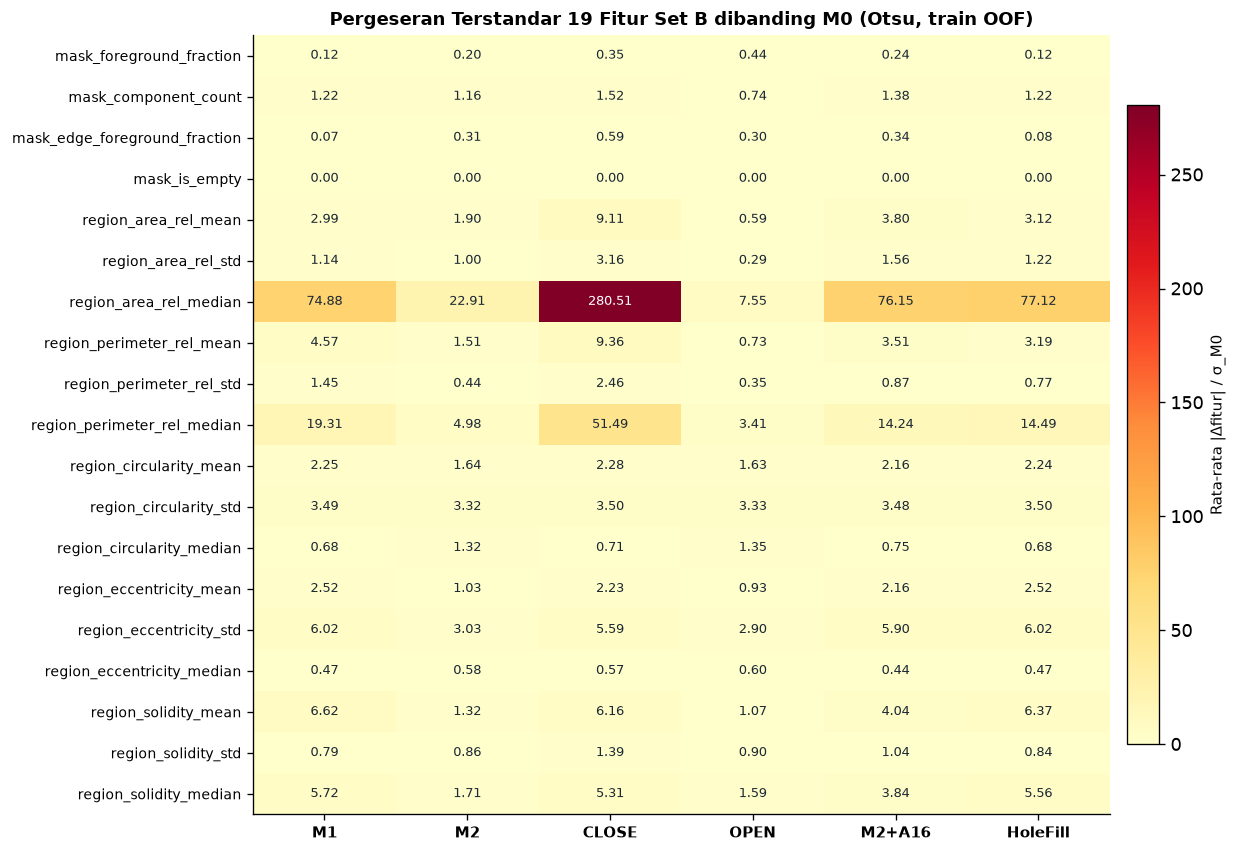

In [9]:
fig_fso = plot_ablation_feature_shifts(outputs.feature_shifts, family="otsu")
finish_figure(fig_fso, show=True, close=True)

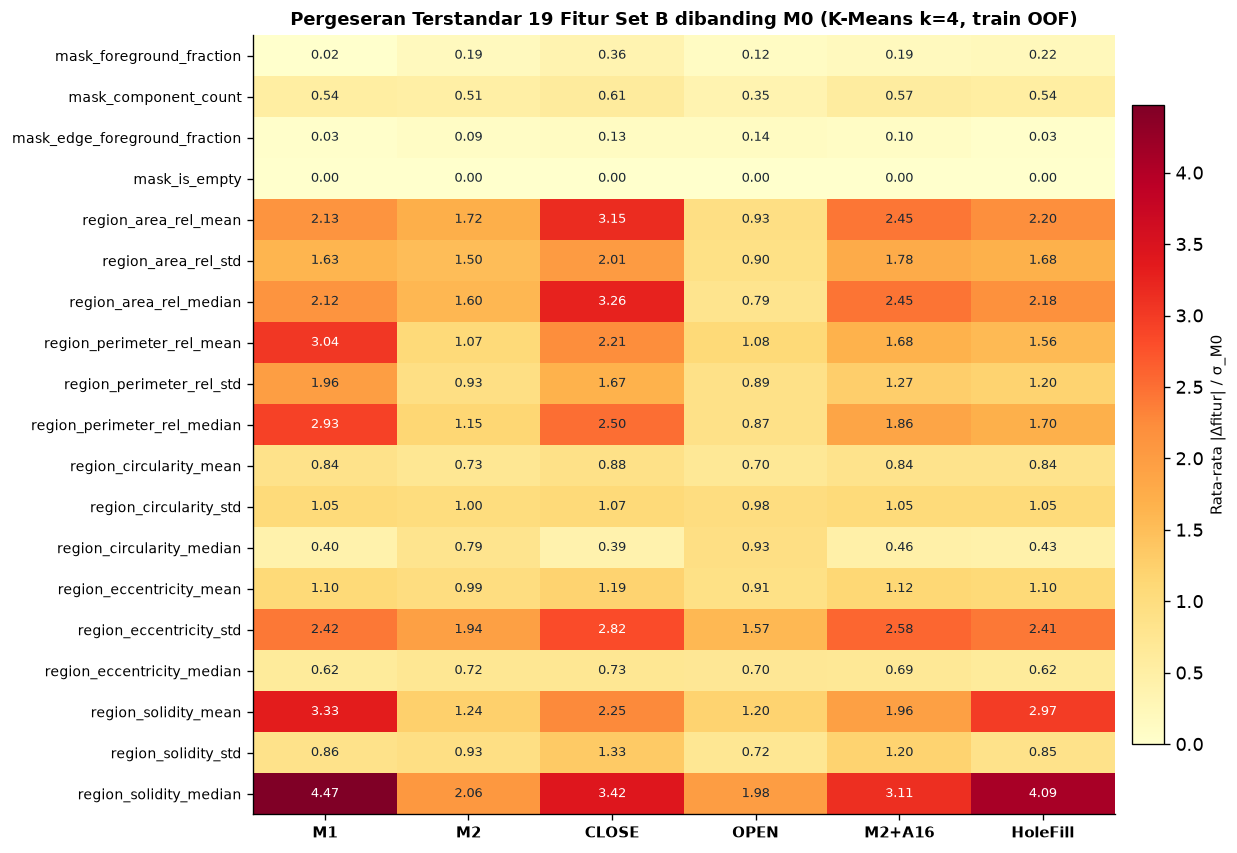

In [10]:
fig_fsk = plot_ablation_feature_shifts(outputs.feature_shifts, family="k4")
finish_figure(fig_fsk, show=True, close=True)

**Interpretasi pergeseran fitur:**
- Menghapus komponen `< 16 px` pada `M1` & `hole_fill_small` menggeser `region_area_rel_median` sebesar **`74,9–77,1 σ_M0`**, `region_perimeter_rel_median` **`14,5–19,3 σ_M0`**, dan `region_solidity_mean` **`6,4–6,6 σ_M0`**.
- `close_only` paling keras mendistorsi statistik bentuk (`region_area_rel_median` **`+280,5 σ_M0`**, `region_area_rel_mean` **`+9,1 σ_M0`**, `mask_edge_foreground_fraction` **`+0,59 σ_M0`**) karena penggabungan kelenjar menaikkan rerata luas komponen `246 -> 3.226 px`.
- Sebaliknya, `open_only` dan `M2` memunculkan kembali populasi fragmen `< 16 px` (`36%` komponen) sehingga pergeseran fitur ukuran median justru paling dekat dengan `M0` (`7,5 σ` pada `open_only`, `22,9 σ` pada `M2`).

## 3. Evaluasi Klasifikasi `StratifiedGroupKFold` (5 Fold, Validation-Blind)

Semua perbandingan di bawah dipasangkan secara identik pada 5 fold yang sama dan *anchor SVM specs* yang sudah ditetapkan sebelum melihat hasil ablasi. Metrik utama adalah **grouped-CV Macro-F1**.

In [11]:
cv = outputs.cv_results.copy()
m0_ref = (
    cv.loc[cv["is_primary_matched_spec"] & cv["variant"].eq("M0"), ["family", "feature_set", "cv_macro_f1"]]
    .rename(columns={"cv_macro_f1": "matched_m0_f1"})
)
cv_view = cv.loc[cv["is_primary_matched_spec"] | cv["is_best_anchor_cv"]].merge(
    m0_ref, on=["family", "feature_set"], how="left"
)
cv_view["delta_vs_matched_M0"] = cv_view["cv_macro_f1"] - cv_view["matched_m0_f1"]
cols_cv = [
    "family", "feature_set", "variant", "spec_id", "is_primary_matched_spec", "is_best_anchor_cv",
    "cv_macro_f1", "delta_vs_matched_M0", "cv_fold_macro_f1_mean", "cv_fold_macro_f1_std",
    "cv_balanced_accuracy", "cv_accuracy",
]
display(
    cv_view[cols_cv].style.format(
        {
            "cv_macro_f1": "{:.4f}",
            "delta_vs_matched_M0": "{:+.4f}",
            "cv_fold_macro_f1_mean": "{:.4f}",
            "cv_fold_macro_f1_std": "{:.4f}",
            "cv_balanced_accuracy": "{:.4f}",
            "cv_accuracy": "{:.4f}",
        }
    )
)

,family,feature_set,variant,spec_id,is_primary_matched_spec,is_best_anchor_cv,cv_macro_f1,delta_vs_matched_M0,cv_fold_macro_f1_mean,cv_fold_macro_f1_std,cv_balanced_accuracy,cv_accuracy
0,shared_A,A,A,rbf_bal_C10_g001,True,True,0.3336,+nan,0.3291,0.0256,0.3886,0.3909
1,otsu,B,M0,rbf_bal_C10_g001,True,True,0.4126,+0.0000,0.4050,0.0237,0.4857,0.4717
2,otsu,C,M0,lin_none_C3,False,True,0.4642,+0.0056,0.4380,0.0570,0.4428,0.5818
3,otsu,C,M0,rbf_bal_C3_g001,True,False,0.4587,+0.0000,0.4544,0.0265,0.5217,0.5127
4,otsu,B,M1,rbf_bal_C10_g001,True,True,0.3789,-0.0337,0.3792,0.0509,0.4416,0.4423
5,otsu,C,M1,rbf_bal_C3_g001,True,True,0.4481,-0.0106,0.4428,0.0125,0.5076,0.5127
6,otsu,B,M2,rbf_bal_C10_g001,True,True,0.4077,-0.0049,0.4077,0.0216,0.4725,0.4834
7,otsu,C,M2,rbf_bal_C3_g001,True,True,0.4622,+0.0035,0.4647,0.0242,0.5190,0.5498
8,otsu,B,close_only,rbf_bal_C10_g001,True,False,0.3906,-0.0219,0.3906,0.0355,0.4489,0.4723
9,otsu,B,close_only,rbf_bal_C3_scale,False,True,0.3948,-0.0177,0.3948,0.0312,0.4342,0.4886


In [12]:
fd = outputs.fold_deltas.copy()
fd_key = fd.loc[
    ((fd["family"] == "otsu") & fd["feature_set"].eq("B") & fd["spec_id"].eq("rbf_bal_C10_g001"))
    | ((fd["family"] == "otsu") & fd["feature_set"].eq("C") & fd["spec_id"].isin(["lin_none_C3", "rbf_bal_C3_g001", "rbf_bal_C10_g001"]))
    | ((fd["family"] == "k4") & fd["feature_set"].eq("C") & fd["spec_id"].eq("rbf_bal_C3_scale"))
].copy()
fd_summary = (
    fd_key.groupby(["family", "feature_set", "spec_id", "variant"], observed=True)
    .agg(
        fold_mean=("macro_f1", "mean"),
        fold_std=("macro_f1", lambda s: float(np.std(s, ddof=0))),
        d_vs_M0=("delta_f1_vs_M0", "mean"),
        wins_M0=("delta_f1_vs_M0", lambda s: f"{int((s > 0).sum())}/5"),
        d_vs_M1=("delta_f1_vs_M1", "mean"),
        wins_M1=("delta_f1_vs_M1", lambda s: f"{int((s > 0).sum())}/5"),
        d_vs_M2=("delta_f1_vs_M2", "mean"),
        wins_M2=("delta_f1_vs_M2", lambda s: f"{int((s > 0).sum())}/5"),
    )
    .reindex(
        [
            (f, fs, sp, v)
            for f, fs, sp in [
                ("otsu", "B", "rbf_bal_C10_g001"),
                ("otsu", "C", "lin_none_C3"),
                ("otsu", "C", "rbf_bal_C3_g001"),
                ("otsu", "C", "rbf_bal_C10_g001"),
                ("k4", "C", "rbf_bal_C3_scale"),
            ]
            for v in ALL_VARIANTS
        ]
    )
    .reset_index()
)
display(
    fd_summary.style.format(
        {
            "fold_mean": "{:.4f}",
            "fold_std": "{:.4f}",
            "d_vs_M0": "{:+.4f}",
            "d_vs_M1": "{:+.4f}",
            "d_vs_M2": "{:+.4f}",
        }
    )
)

,family,feature_set,spec_id,variant,fold_mean,fold_std,d_vs_M0,wins_M0,d_vs_M1,wins_M1,d_vs_M2,wins_M2
0,otsu,B,rbf_bal_C10_g001,M0,0.4050,0.0237,+0.0000,0/5,+0.0258,3/5,-0.0026,3/5
1,otsu,B,rbf_bal_C10_g001,M1,0.3792,0.0509,-0.0258,2/5,+0.0000,0/5,-0.0285,2/5
2,otsu,B,rbf_bal_C10_g001,M2,0.4077,0.0216,+0.0026,2/5,+0.0285,3/5,+0.0000,0/5
3,otsu,B,rbf_bal_C10_g001,close_only,0.3906,0.0355,-0.0144,3/5,+0.0114,3/5,-0.0171,2/5
4,otsu,B,rbf_bal_C10_g001,open_only,0.3840,0.0292,-0.0211,2/5,+0.0048,2/5,-0.0237,1/5
5,otsu,B,rbf_bal_C10_g001,m2_area16,0.3748,0.0268,-0.0303,2/5,-0.0044,3/5,-0.0329,0/5
6,otsu,B,rbf_bal_C10_g001,hole_fill_small,0.3941,0.0489,-0.0110,2/5,+0.0149,3/5,-0.0136,3/5
7,otsu,C,lin_none_C3,M0,0.4380,0.0570,+0.0000,0/5,+0.0627,4/5,-0.0041,4/5
8,otsu,C,lin_none_C3,M1,0.3753,0.0253,-0.0627,1/5,+0.0000,0/5,-0.0668,0/5
9,otsu,C,lin_none_C3,M2,0.4421,0.0229,+0.0041,1/5,+0.0668,5/5,+0.0000,0/5


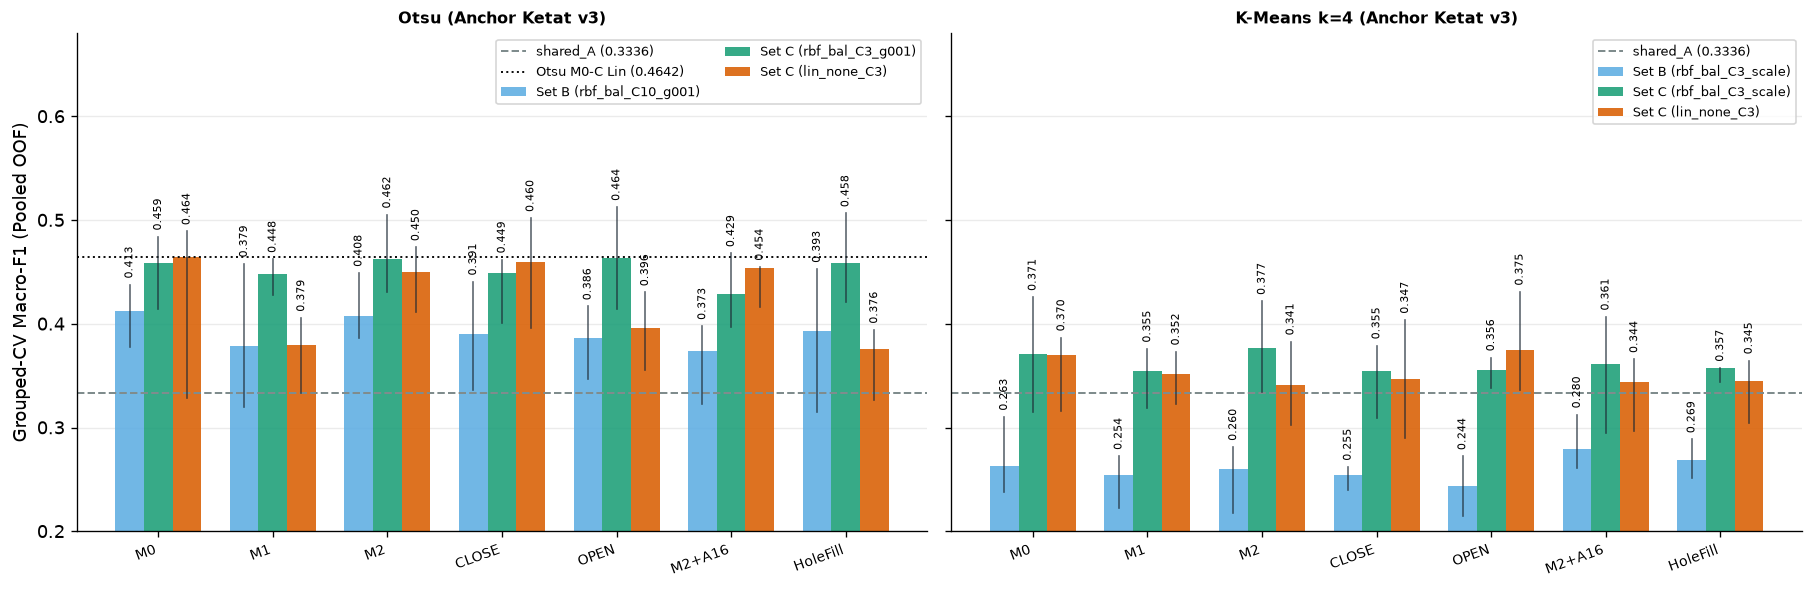

In [13]:
fig_cv = plot_ablation_cv_macro_f1(outputs.cv_results, outputs.fold_deltas)
finish_figure(fig_cv, show=True, close=True)

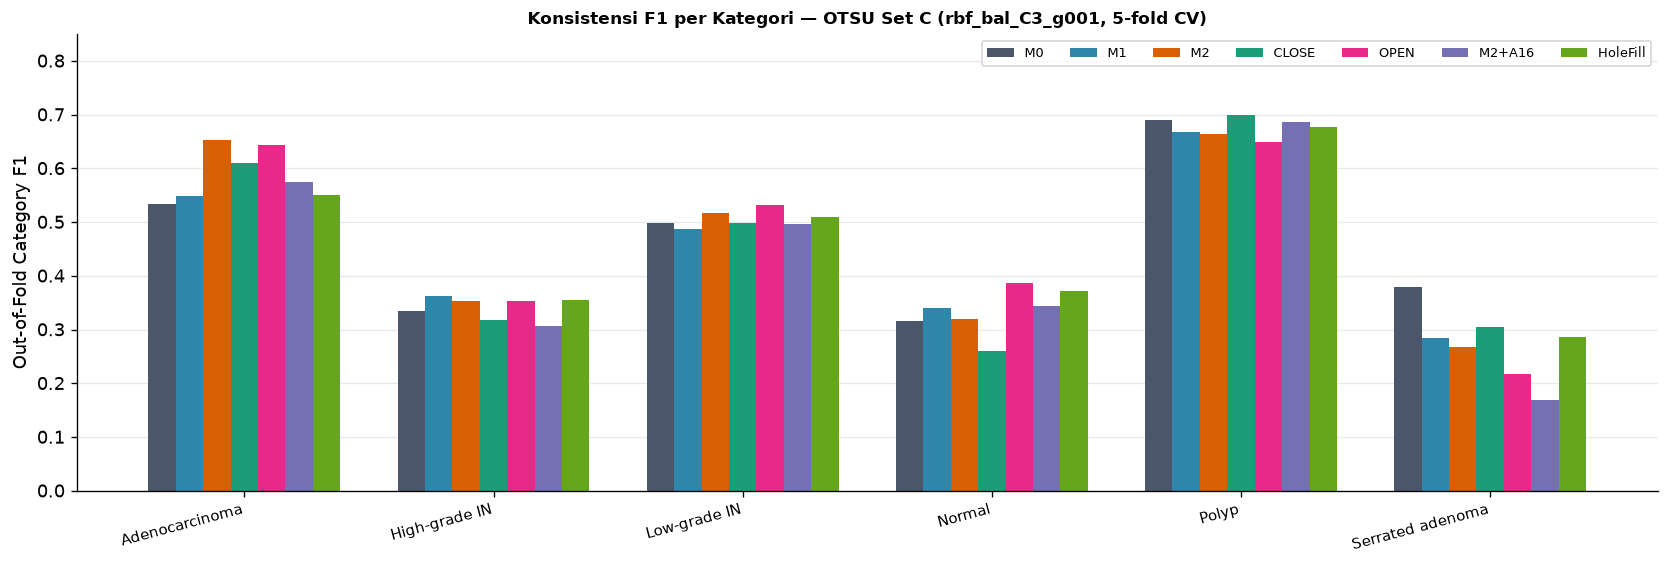

In [14]:
fig_cat_otsu = plot_ablation_per_category_f1(
    outputs.per_category_cv, family="otsu", feature_set="C", spec_id="rbf_bal_C3_g001"
)
finish_figure(fig_cat_otsu, show=True, close=True)

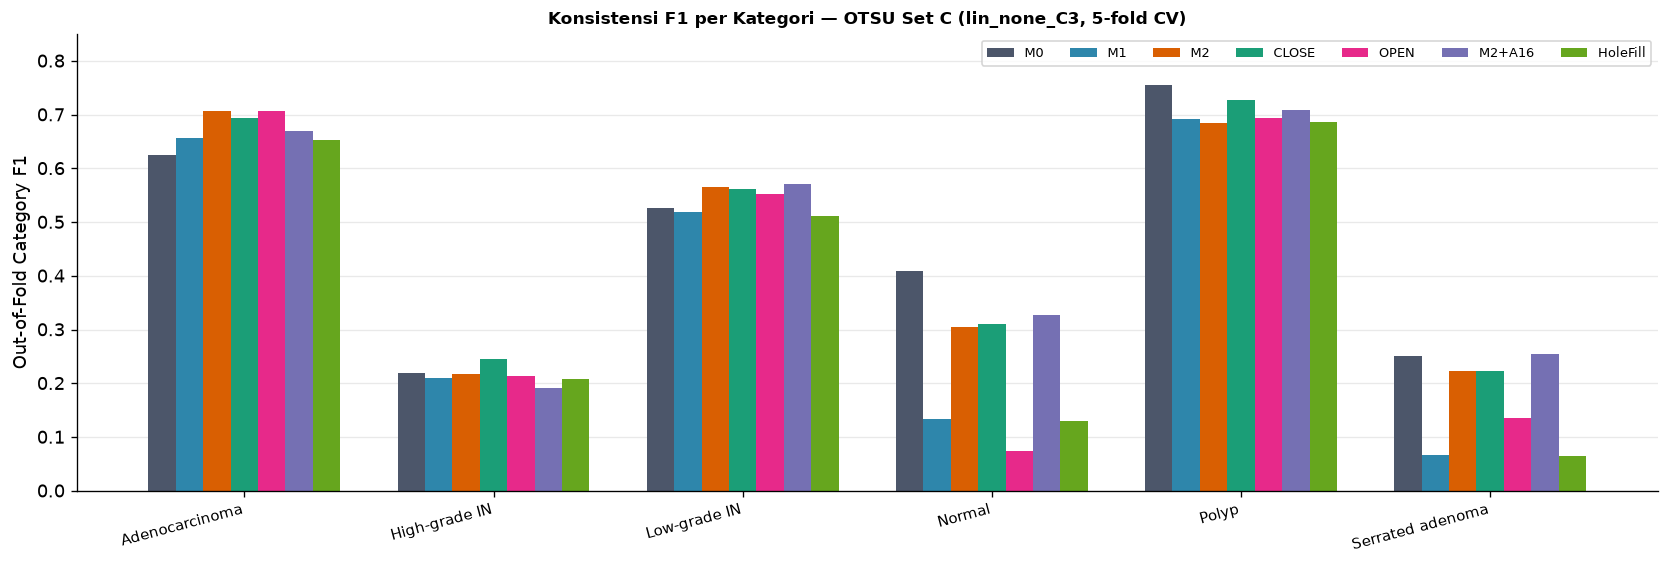

In [15]:
fig_cat_lin = plot_ablation_per_category_f1(
    outputs.per_category_cv, family="otsu", feature_set="C", spec_id="lin_none_C3"
)
finish_figure(fig_cat_lin, show=True, close=True)

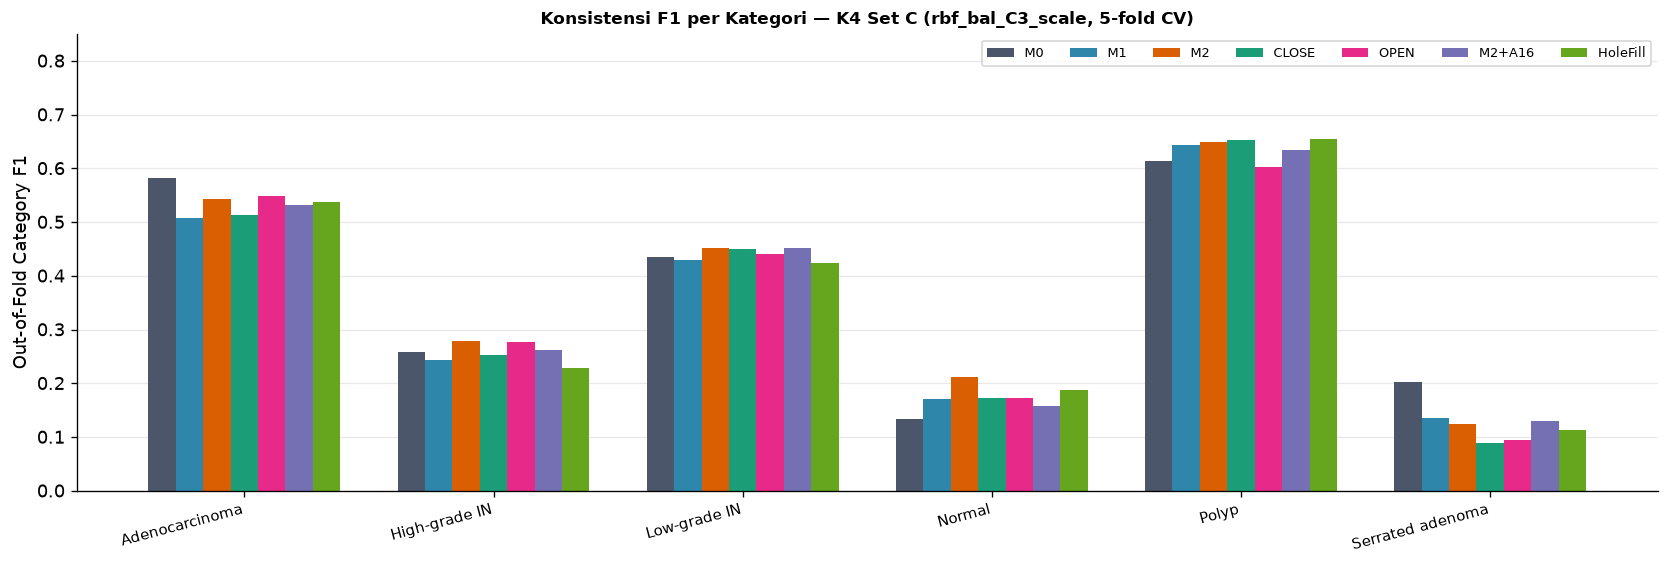

In [16]:
fig_cat_k4 = plot_ablation_per_category_f1(
    outputs.per_category_cv, family="k4", feature_set="C", spec_id="rbf_bal_C3_scale"
)
finish_figure(fig_cat_k4, show=True, close=True)

**Analisis klasifikasi & konsistensi lintas fold/kategori:**
1. **Pada `Set B` murni (Otsu, `rbf_bal_C10_g001`), `M0` (`0.4126`) tetap tertinggi:** seluruh pascaproses menurunkan fitur bentuk murni (`M1=0.3789`, `close_only=0.3906`, `open_only=0.3863`, `hole_fill_small=0.3930`). `m2_area16` bahkan merosot menjadi **`0.3735` (kalah di `5/5` fold vs `M2`)**, dan pada `Set C rbf_bal_C3_g001` turun ke **`0.4291` vs `M2 0.4622` (`-0.0407` mean fold)**. Artinya, daya klasifikasi `M2` di atas `M1` justru disumbang oleh fragmen kecil residu *opening* (`24,5` fragmen `< 16 px` yang dipertahankan `M2`), bukan oleh penyederhanaan makro-kontur!
2. **`close_only` (Dice Otsu tertinggi `0.7001`) gagal mengungguli `M0` di klasifikasi:** pada `Set B` hanya `0.3906` (`-0.0220` vs `M0`), pada `Set C` matched `0.4487` (vs `M0 0.4587`) dan best anchor `0.4627` (vs `M0 0.4642`). *Over-merging* mengaburkan granularitas inti antar-kelas diagnostik.
3. **`hole_fill_small` memulihkan performa `M1` tetapi tertahan oleh penghapusan `< 16 px` sebelumnya:** pada Otsu `Set C rbf_bal_C3_g001`, ia menyamai `M0` (`0.4582` vs `0.4587`, menang `3/5` fold vs `M0` dan `4/5` fold vs `M1`), namun di `lin_none_C3` jatuh (`0.3757` vs `M0 0.4642`) dan di `Set B` tetap tertinggal (`0.3930` vs `M0 0.4126`).
4. **`open_only` berfluktuasi tinggi:** memangkas sedikit keunggulan nominal di `Otsu Set C rbf_bal_C10_g001` (`0.4692`, hanya `+0.0050` atas `M0 lin_none_C3 0.4642`), namun runtuh di `lin_none_C3` (`0.3960`) serta menjatuhkan F1 kelas langka **`Serrated adenoma` (`0.3793 M0 -> 0.2177 open_only`)** dan `Polyp`.
5. **Keluarga `k4` tetap jauh di bawah `Otsu`:** semua varian `k4 Set C` berkisar `0.355–0.378` (`~0.09` lebih rendah daripada `Otsu`).

## 4. Galeri Visual Kasus Deterministik (`train` Split)

Pemilihan kasus dilakukan deterministik dari data `train`: (a) kenaikan Dice terbesar `CLOSE-only vs M0`, (b) erosi `Polyp` oleh `OPEN-only vs M1`, (c) manfaat `HoleFill <= 15 px`, dan (d) contoh nyata **Dice meningkat namun prediksi OOF berbalik salah (`Dice Up / Cls Flip`)** pada `M2` maupun `CLOSE-only`.

In [17]:
display(
    outputs.deterministic_cases.style.format(
        {
            "dice_M0": "{:.4f}",
            "dice_M1": "{:.4f}",
            "dice_M2": "{:.4f}",
            "dice_close": "{:.4f}",
            "dice_m2a16": "{:.4f}",
            "dice_hole": "{:.4f}",
        }
    )
)

,role,target_variant,sample_id,category,group_id,dice_M0,dice_M1,dice_M2,dice_close,dice_m2a16,dice_hole,ok_M0,ok_M1,ok_M2,ok_close_only,ok_m2_area16,ok_hole_fill_small
0,Max Dice Gain (CLOSE-only vs M0),close_only,High-grade IN/GTXC2015403-1-400-004,High-grade IN,GTXC2015403,0.7049,0.7060,0.7052,0.7901,0.7028,0.7440,False,False,False,False,False,False
1,Polyp Erosion (OPEN-only vs M1),open_only,Polyp/GT2012154-2-400-001,Polyp,GT2012154,0.6180,0.6176,0.5869,0.6427,0.5809,0.6327,False,False,False,False,True,False
2,Max HoleFill Gain (vs M1),hole_fill_small,High-grade IN/GT2016887-2-400-001,High-grade IN,GT2016887,0.8029,0.8023,0.8215,0.8491,0.8213,0.8434,True,False,False,False,False,False
3,Dice Up / Cls Flip (M2 vs M0),M2,High-grade IN/GTxc2013501-3-400-005,High-grade IN,GTXC2013501,0.8212,0.8262,0.8411,0.8522,0.8416,0.8516,True,False,False,True,True,False


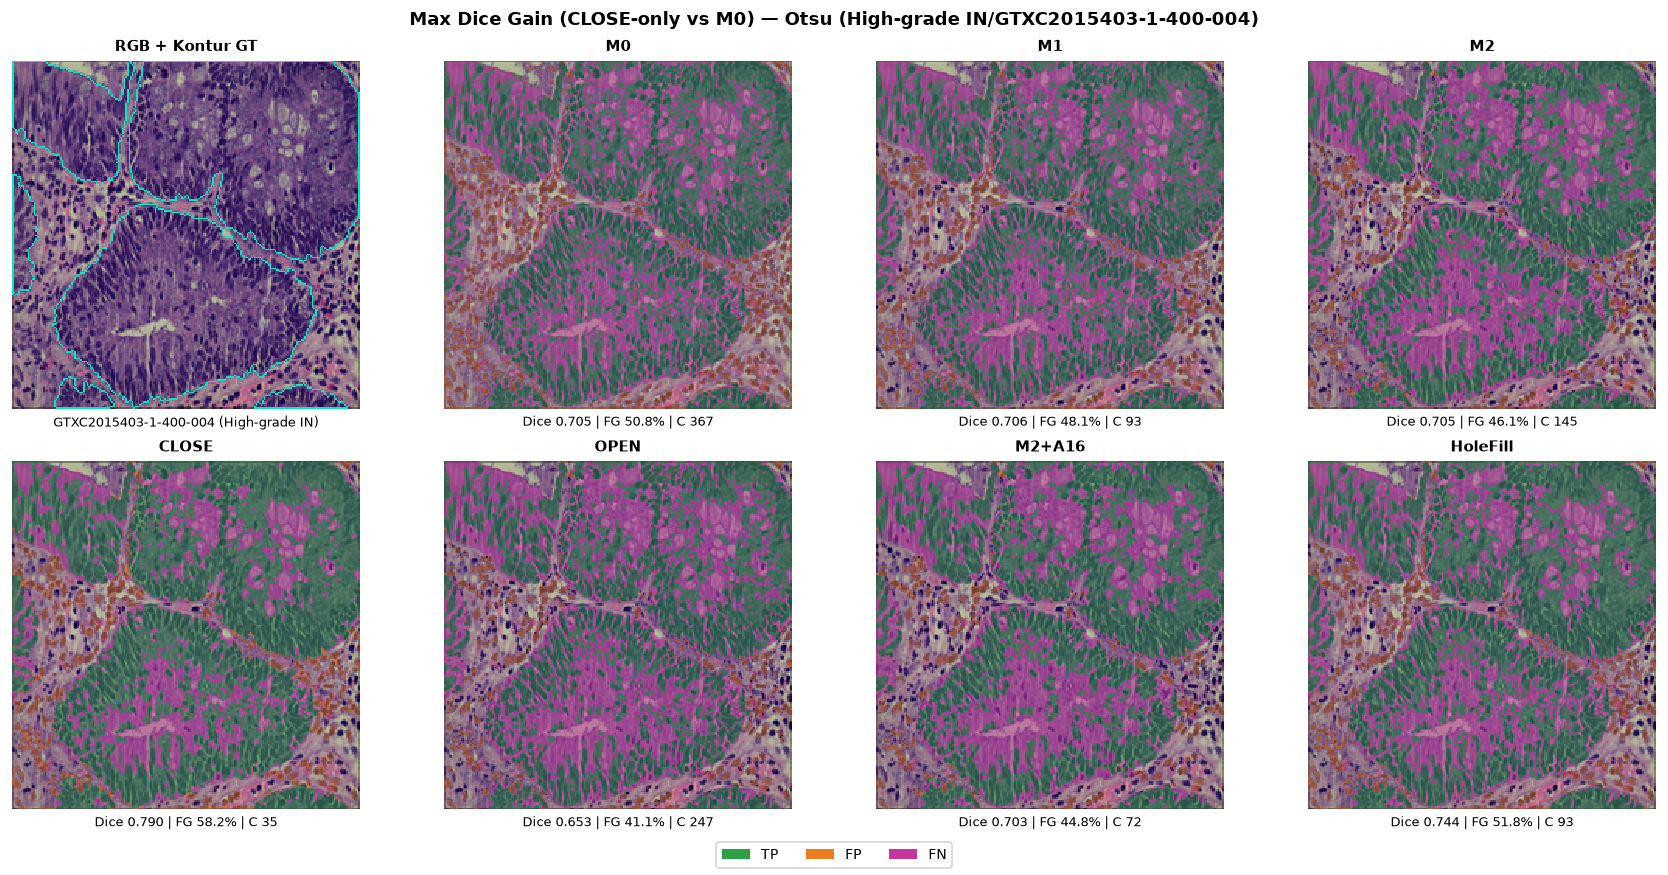

In [18]:
row0 = outputs.deterministic_cases.iloc[0]
fig_g0 = plot_case_ablation_gallery(
    ROOT, str(row0["sample_id"]), family="otsu",
    title_prefix=f"{row0['role']} — Otsu ({row0['sample_id']})"
)
finish_figure(fig_g0, show=True, close=True)

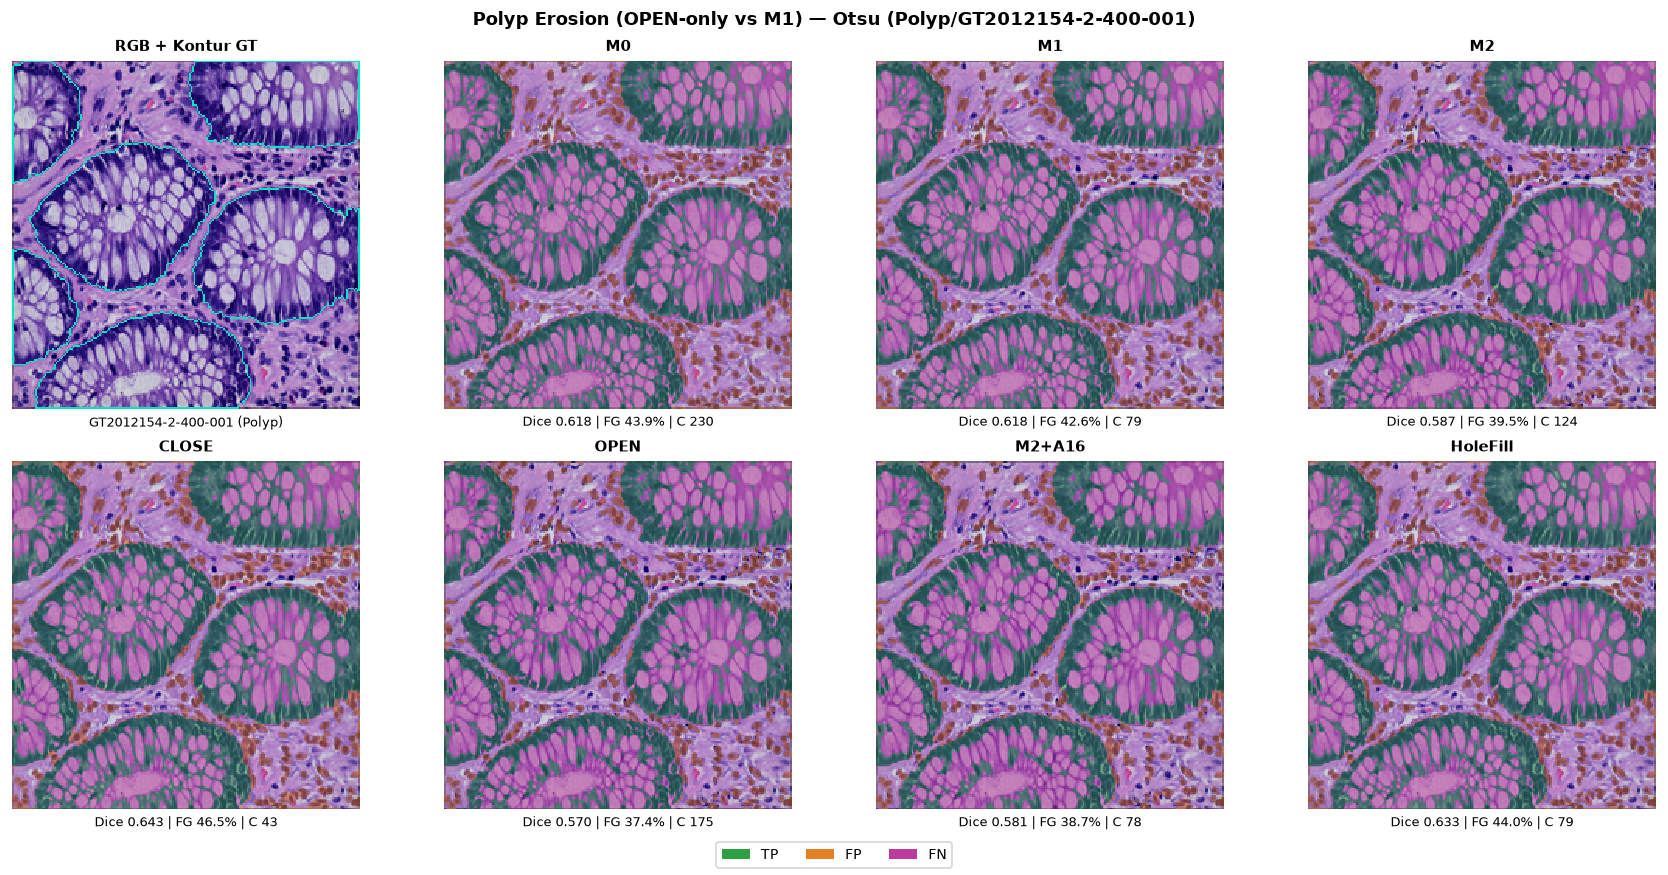

In [19]:
row1 = outputs.deterministic_cases.iloc[1]
fig_g1 = plot_case_ablation_gallery(
    ROOT, str(row1["sample_id"]), family="otsu",
    title_prefix=f"{row1['role']} — Otsu ({row1['sample_id']})"
)
finish_figure(fig_g1, show=True, close=True)

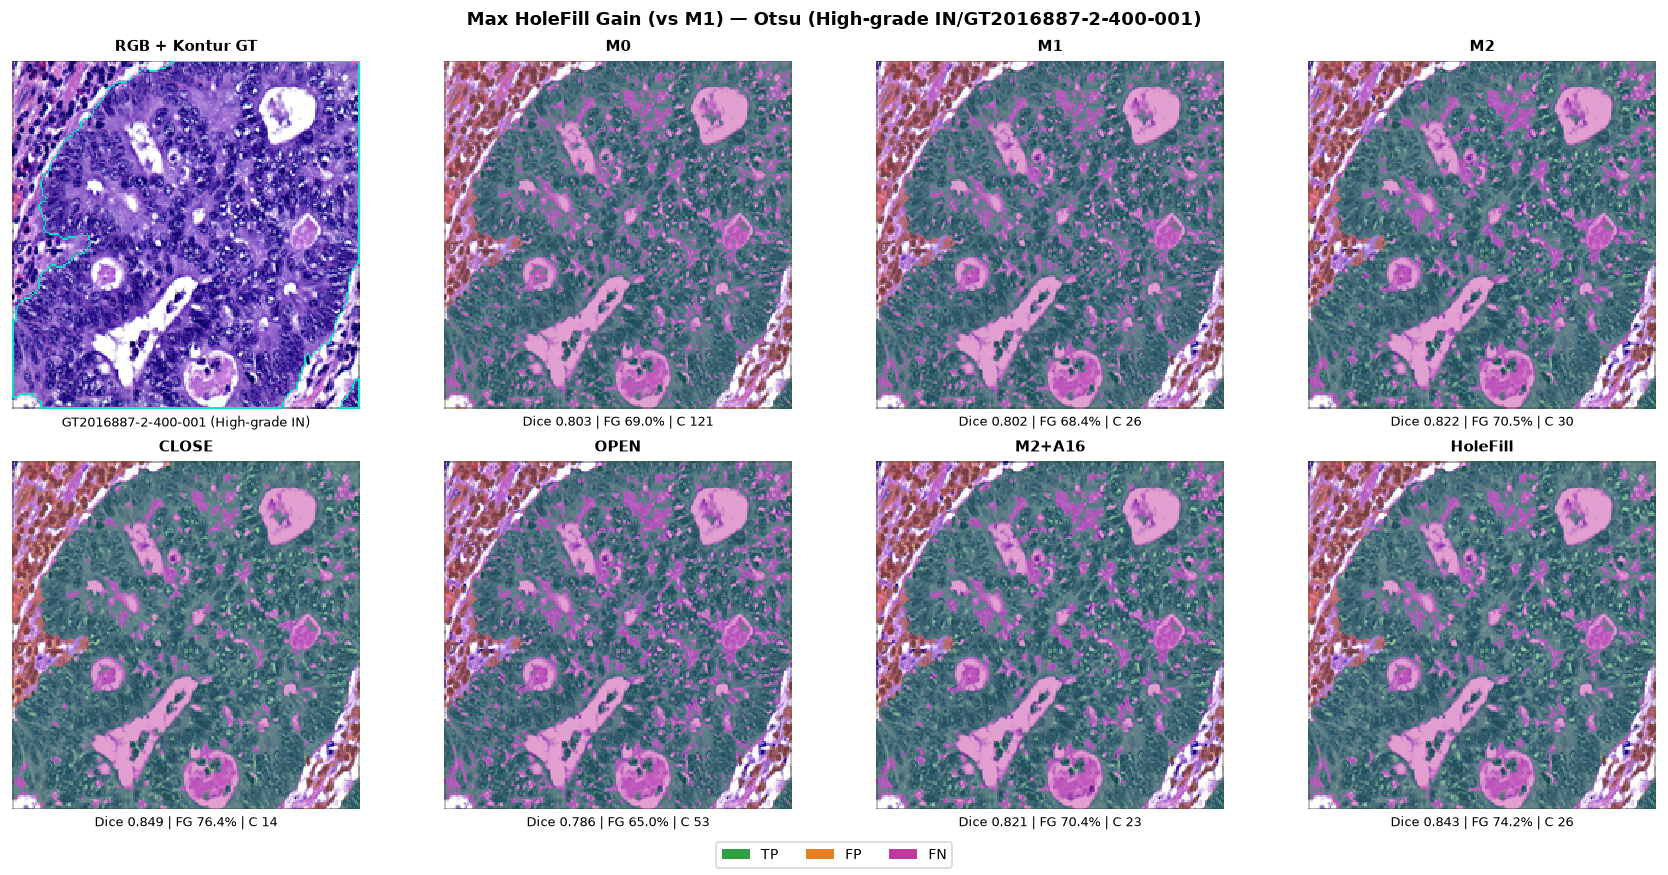

In [20]:
row2 = outputs.deterministic_cases.iloc[2]
fig_g2 = plot_case_ablation_gallery(
    ROOT, str(row2["sample_id"]), family="otsu",
    title_prefix=f"{row2['role']} — Otsu ({row2['sample_id']})"
)
finish_figure(fig_g2, show=True, close=True)

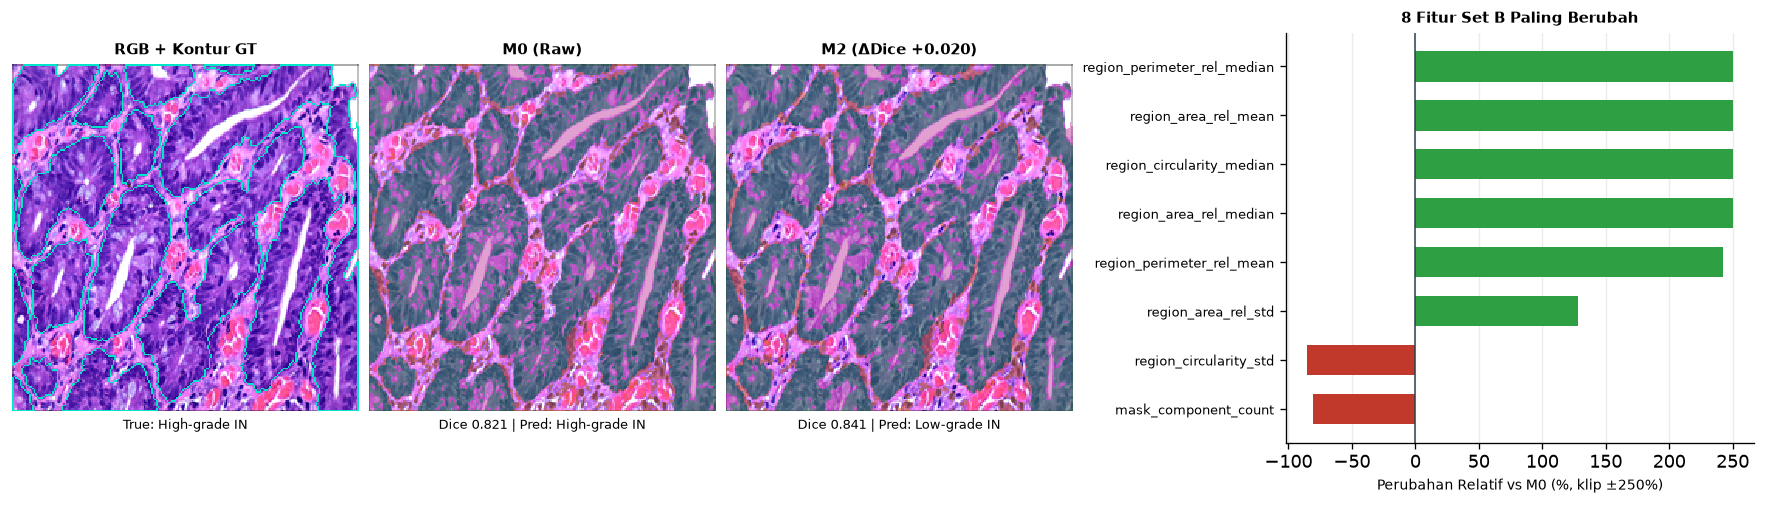

In [21]:
row3 = outputs.deterministic_cases.iloc[3]
fig_flip_m2 = plot_dice_up_cls_flip_example(
    ROOT, str(row3["sample_id"]), "M2", outputs.oof_predictions, family="otsu", spec_id="rbf_bal_C3_g001"
)
finish_figure(fig_flip_m2, show=True, close=True)

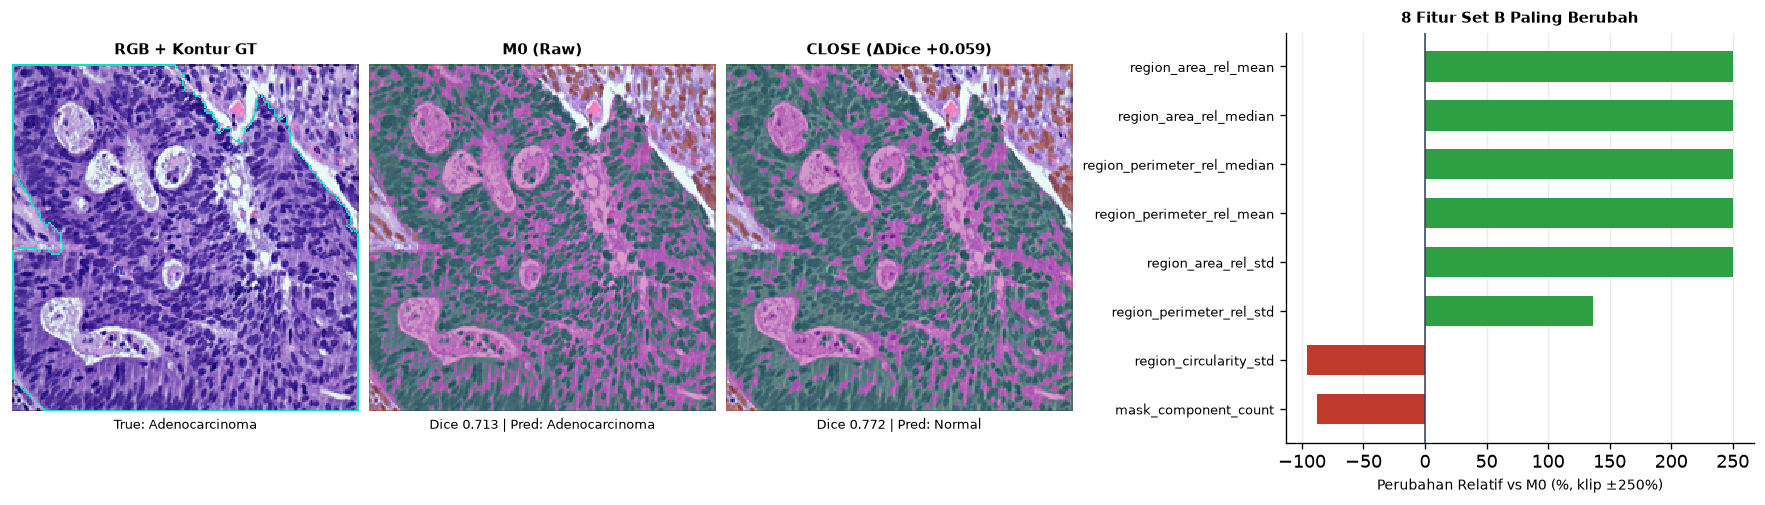

In [22]:
fig_flip_close = plot_dice_up_cls_flip_example(
    ROOT, "Adenocarcinoma/GT2014662-2-400-001", "close_only", outputs.oof_predictions, family="otsu", spec_id="rbf_bal_C3_g001"
)
finish_figure(fig_flip_close, show=True, close=True)

## 5. Jawaban Pertanyaan Ilmiah & Verifikasi Integritas

1. **Apakah `CLOSE-only` lebih baik daripada `M2`?** **Untuk segmentasi Otsu ya (`+0.0183` Dice di atas `M2`), namun untuk klasifikasi tidak (`Set B 0.3906` vs `M2 0.4077` dan `M0 0.4126`)**, karena *closing* menggabungkan komponen nuklear dan menggeser `region_area_rel_median` (`+280,5 σ_M0`).
2. **Apakah *opening* (`OPEN-only` / `M2`) menghapus struktur diskriminatif berguna atau justru menjadi sumber fragmentasi?** **`OPEN-only` jelas mengikis jaringan tipis (`-0.0141` Dice vs `M0`) dan memproduksi `41,3` fragmen `< 16 px` baru per citra;** ironisnya, fragmen mikro yang tersisa di `M2` (`24,5` komponen `< 16 px`) justru memberi sinyal tekstur/kepadatan yang membantu klasifikasi `Adenocarcinoma` sementara menurunkan `Serrated adenoma`.
3. **Apakah penghapusan fragmen setelah `M2` (`m2_area16`) membantu atau merugikan?** **Merugikan kedua sisi secara konsisten pada Otsu:** menurunkan Dice sedikit (`0.6818 -> 0.6809`) dan menjatuhkan `CV Macro-F1` (`Set B` turun `-0.0342`, kalah `5/5` fold vs `M2`; `Set C rbf_bal_C3_g001` turun `0.4622 -> 0.4291`). Pada `k4`, `m2_area16` hanya membantu sedikit pada `Set B` (`0.2797` vs `0.2596`).
4. **Apakah *selective hole filling* (`hole_fill_small <= 15 px`) memperbaiki Dice sekaligus menjaga fitur klasifikasi?** **Ya di segmentasi (`+0.0111` Dice, `1.305/1.535` naik vs `M1`, hanya 5 turun), namun belum melampaui `M0` di klasifikasi (`Set C 0.4582` vs `0.4587`; `Set B 0.3930` vs `0.4126`)** karena langkah prasyarat `M1` tetap menghilangkan fragmen kecil `< 16 px` yang informatif.
5. **Apakah ada kandidat yang mengungguli `M0` dan `M2` secara konsisten lintas fold & kategori di `CV Macro-F1`?** **Tidak ada kandidat pascaproses mask yang konsisten mengungguli baseline terbaik `Otsu M0` (`0.4642 lin_none_C3`, `0.4126 Set B`) di seluruh fold dan ke-6 kategori.**
6. **Mengapa perbaikan Dice kecil tidak otomatis meningkatkan klasifikasi?** **Karena Dice mengukur kesepakatan area piksel global (`overlap` dominan oleh regio kelenjar besar), sedangkan `Set B` merangkum ringkasan statistik komponen (seperti kepadatan fragmen kecil, *median area*, dan *solidity*) — menghapus atau menggabung titik nuklear dapat menaikkan Dice sekaligus menghapus sinyal histopatologis antar-kelas.**

In [23]:
hashes_after = file_sha256_map(ROOT, TRACKED_INPUTS)
assert hashes_after == input_hashes_before, "Input file mutation detected!"
print("Integrity OK: 0 held-out test accessed; frozen split, models, and historical CSVs unchanged.")

Integrity OK: 0 held-out test accessed; frozen split, models, and historical CSVs unchanged.
